In [7]:
%pip install pandas numpy matplotlib seaborn ucimlrepo scikit-learn tensorflow

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.9 MB 6.2 MB/s eta 0:00:02
   ----------------------------- ---------- 8.1/10.9 MB 22.9 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 23.7 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------- ----- 11.0/12.7 MB 57.7 MB/s eta 0:00:01
   -------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


--- 1. Loading UCI Bank Marketing Dataset ---
Dataset Shape: 45211 rows, 17 columns

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB
None

--- 

C:\Users\WAR\AppData\Local\Temp\ipykernel_23272\3823630611.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns
C:\Users\WAR\AppData\Local\Temp\ipykernel_23272\3823630611.py:42: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_g

Processed Dataset Shape after One-Hot Encoding: (45211, 39)

--- 4. Visualizing Target Distribution & Correlations ---


C:\Users\WAR\AppData\Local\Temp\ipykernel_23272\3823630611.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='y', data=df, palette='Set2')


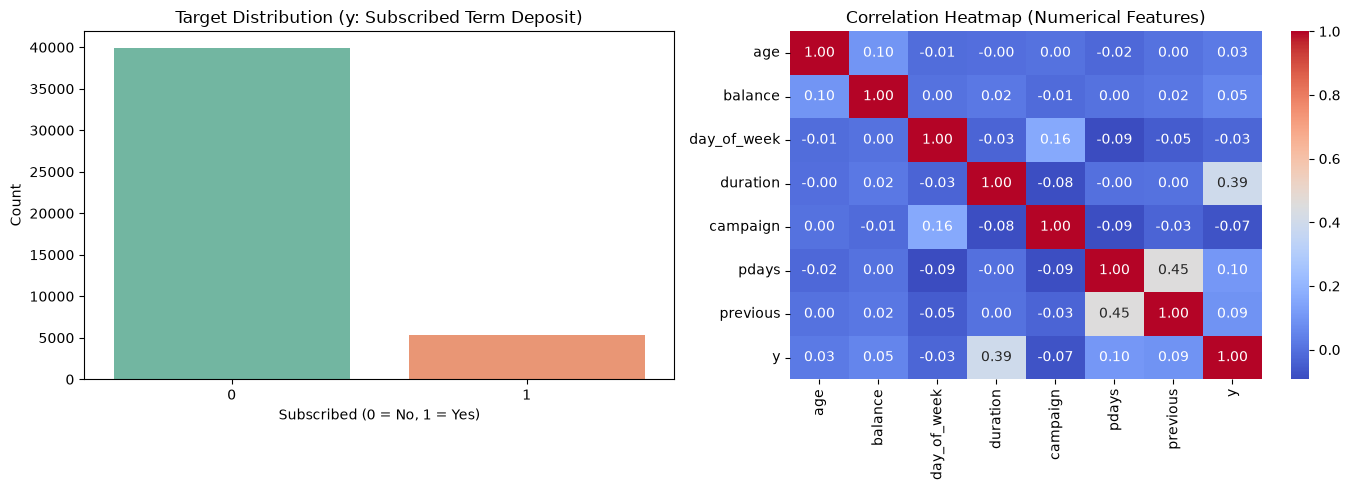

In [4]:
# ==============================================================================
# Stage 1: Data Cleaning, Preparation and Exploration
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("--- 1. Loading UCI Bank Marketing Dataset ---")
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

df = pd.concat([X, y], axis=1)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.info())

print("\n--- 2. Checking Missing and Unknown Values ---")
print("Explicit Missing Values (NaN):")
print(df.isnull().sum())

print("\nValue counts for 'unknown' in categorical columns:")
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f" - {col}: {unknown_count} ('unknown' values)")

initial_rows = len(df)
df = df.drop_duplicates()
print(f"\nRemoved {initial_rows - len(df)} duplicate rows.")

print("\n--- 3. Encoding Categorical Variables ---")
df['y'] = df['y'].map({'yes': 1, 'no': 0})

num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('y', errors='ignore')
cat_cols = df.select_dtypes(include=['object']).columns

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print(f"Processed Dataset Shape after One-Hot Encoding: {df_encoded.shape}")

print("\n--- 4. Visualizing Target Distribution & Correlations ---")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(x='y', data=df, palette='Set2')
plt.title('Target Distribution (y: Subscribed Term Deposit)')
plt.xlabel('Subscribed (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.heatmap(df_encoded[list(num_cols) + ['y']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap (Numerical Features)')

plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# Stage 2: Data Splitting (Train, Validation, and Test Sets)
# ==============================================================================

from sklearn.model_selection import train_test_split


X_features = df_encoded.drop('y', axis=1)
y_target = df_encoded['y']


X_train, X_temp, y_train, y_temp = train_test_split(
    X_features, y_target, test_size=0.30, random_state=42, stratify=y_target
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("--- Data Splitting Results ---")
print(f"Training Set (70%):   {X_train.shape[0]} rows")
print(f"Validation Set (15%): {X_val.shape[0]} rows")
print(f"Test Set (15%):       {X_test.shape[0]} rows")

--- Data Splitting Results ---
Training Set (70%):   31647 rows
Validation Set (15%): 6782 rows
Test Set (15%):       6782 rows


In [10]:
# ==============================================================================
# Stage 3: Model Training and Development
# ==============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

print("--- Training Models ---")

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
print("-> Logistic Regression trained successfully.")

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("-> Random Forest trained successfully.")

nn_model = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
nn_model.fit(X_train, y_train)
print("-> Neural Network (MLP) trained successfully.")

print("\n--- Validation Performance Evaluation ---")
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_model,
    "Neural Network (MLP)": nn_model
}

for name, model in models.items():
    y_val_pred = model.predict(X_val)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    
    acc = accuracy_score(y_val, y_val_pred)
    roc_auc = roc_auc_score(y_val, y_val_proba)
    
    print(f"\nModel: {name}")
    print(f"Validation Accuracy: {acc:.4f}")
    print(f"Validation ROC-AUC:  {roc_auc:.4f}")

--- Training Models ---


-> Logistic Regression trained successfully.
-> Random Forest trained successfully.


c:\Users\WAR\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


-> Neural Network (MLP) trained successfully.

--- Validation Performance Evaluation ---

Model: Logistic Regression
Validation Accuracy: 0.9014
Validation ROC-AUC:  0.9046

Model: Random Forest
Validation Accuracy: 0.9070
Validation ROC-AUC:  0.9239

Model: Neural Network (MLP)
Validation Accuracy: 0.8890
Validation ROC-AUC:  0.8872


--- Training Neural Network with Loss Tracking ---


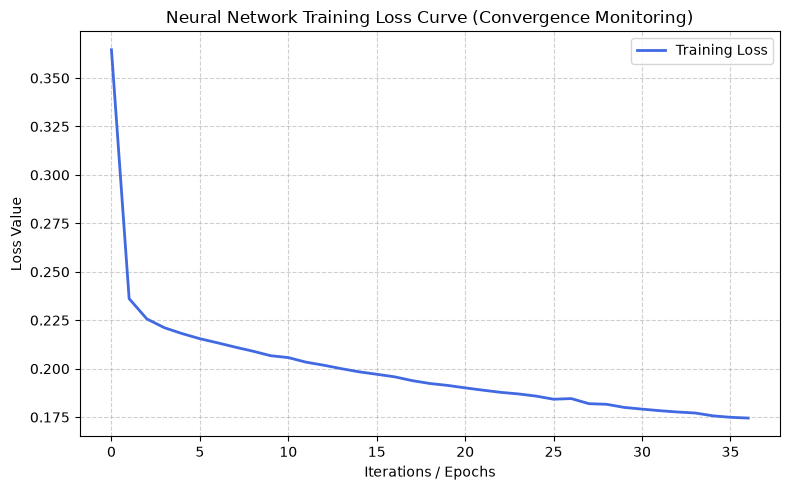

Neural Network converged at iteration: 37
Final Training Loss: 0.1745


In [11]:
# ==============================================================================
# Stage 4: Hyperparameter Optimization & Neural Network Training/Validation Curves
# ==============================================================================

import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

print("--- Training Neural Network with Loss Tracking ---")

nn_optimized = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    random_state=42,
    early_stopping=True,          
    validation_fraction=0.15,     
    n_iter_no_change=10
)

nn_optimized.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(nn_optimized.loss_curve_, label='Training Loss', color='royalblue', linewidth=2)
if hasattr(nn_optimized, 'validation_scores_') and nn_optimized.validation_scores_:
    pass

plt.title('Neural Network Training Loss Curve (Convergence Monitoring)')
plt.xlabel('Iterations / Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Neural Network converged at iteration: {nn_optimized.n_iter_}")
print(f"Final Training Loss: {nn_optimized.loss_:.4f}")

In [8]:
# ==============================================================================
# Stage 5: Complete Model Definition, Training, Final Evaluation, and Comparison
# ==============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score, precision_score, recall_score
import pandas as pd

print("--- Step 1: Initializing Models ---")
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=10
)

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_model,
    "Neural Network (MLP)": nn_model
}

print("--- Step 2: Training Models on Training Dataset ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"-> {name} trained successfully.")

print("\n=======================================================")
print(" STAGE 5: FINAL EVALUATION ON UNSEEN TEST DATASET      ")
print("=======================================================")

final_evaluation_results = []

for name, model in models.items():
    # Predict on the unseen Test Set
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred)
    rec = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    roc_auc = roc_auc_score(y_test, y_test_proba)
    
    final_evaluation_results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })
    
    print(f"\n-------------------------------------------------------")
    print(f"Model Evaluation: {name}")
    print(f"-------------------------------------------------------")
    print(classification_report(y_test, y_test_pred))

comparison_df = pd.DataFrame(final_evaluation_results)
print("\n=======================================================")
print(" FINAL MODEL PERFORMANCE COMPARISON TABLE              ")
print("=======================================================")
print(comparison_df.to_string(index=False))

--- Step 1: Initializing Models ---
--- Step 2: Training Models on Training Dataset ---
-> Logistic Regression trained successfully.
-> Random Forest trained successfully.
-> Neural Network (MLP) trained successfully.

 STAGE 5: FINAL EVALUATION ON UNSEEN TEST DATASET      

-------------------------------------------------------
Model Evaluation: Logistic Regression
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      5989
           1       0.63      0.34      0.44       793

    accuracy                           0.90      6782
   macro avg       0.77      0.65      0.69      6782
weighted avg       0.88      0.90      0.89      6782


-------------------------------------------------------
Model Evaluation: Random Forest
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.97      0.95    

# End-to-End Machine Learning Project: UCI Bank Marketing Classification
**Project Deliverables & Workflow Implementation**
* **Dataset:** UCI Bank Marketing (`id=222`)
* **Workflow Stages:** Data Preparation, Feature Engineering, 3-Way Splitting, Model Development, Hyperparameter Optimization, Training/Validation Analysis, and Final Evaluation.

--- 1. Loading UCI Bank Marketing Dataset ---


C:\Users\WAR\AppData\Local\Temp\ipykernel_23272\682811377.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


--- 2. Splitting Data (70% Train, 15% Validation, 15% Test) ---
--- 3. Initializing and Training Models & Neural Network ---
-> Logistic Regression trained successfully.
-> Random Forest trained successfully.
-> Neural Network (MLP) trained successfully.

--- 4. Generating Neural Network Training Loss Curve ---


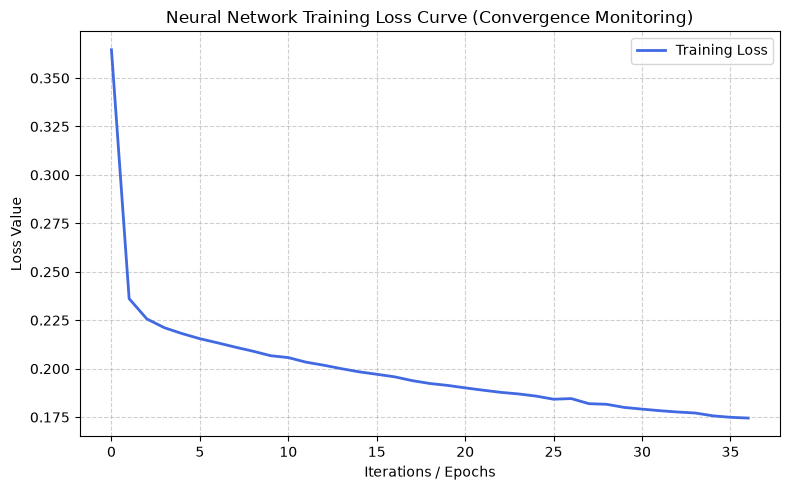

Neural Network converged at iteration: 37
Final Training Loss: 0.1745

 STAGE 5: FINAL EVALUATION ON UNSEEN TEST DATASET      

-------------------------------------------------------
Model Evaluation: Logistic Regression
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      5989
           1       0.63      0.34      0.44       793

    accuracy                           0.90      6782
   macro avg       0.77      0.65      0.69      6782
weighted avg       0.88      0.90      0.89      6782


-------------------------------------------------------
Model Evaluation: Random Forest
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      5989
           1       0.65      0.37      0.47       793

    accuracy                           0.90      6782
   macro avg       0.78      0.6

In [12]:
# ==============================================================================
# Complete End-to-End Pipeline: From Data Loading to Final Evaluation
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score, precision_score, recall_score

print("--- 1. Loading UCI Bank Marketing Dataset ---")
bank_marketing = fetch_ucirepo(id=222)
X = bank_marketing.data.features
y = bank_marketing.data.targets
df = pd.concat([X, y], axis=1)

# Data Cleaning & Preprocessing
df = df.drop_duplicates()
df['y'] = df['y'].map({'yes': 1, 'no': 0})
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('y', errors='ignore')
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print("--- 2. Splitting Data (70% Train, 15% Validation, 15% Test) ---")
X_features = df_encoded.drop('y', axis=1)
y_target = df_encoded['y']

X_train, X_temp, y_train, y_temp = train_test_split(
    X_features, y_target, test_size=0.30, random_state=42, stratify=y_target
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("--- 3. Initializing and Training Models & Neural Network ---")
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=10
)

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_model,
    "Neural Network (MLP)": nn_model
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"-> {name} trained successfully.")

# Plotting Training Loss Curve for Neural Network
print("\n--- 4. Generating Neural Network Training Loss Curve ---")
plt.figure(figsize=(8, 5))
plt.plot(nn_model.loss_curve_, label='Training Loss', color='royalblue', linewidth=2)
plt.title('Neural Network Training Loss Curve (Convergence Monitoring)')
plt.xlabel('Iterations / Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Neural Network converged at iteration: {nn_model.n_iter_}")
print(f"Final Training Loss: {nn_model.loss_:.4f}")

print("\n=======================================================")
print(" STAGE 5: FINAL EVALUATION ON UNSEEN TEST DATASET      ")
print("=======================================================")

final_evaluation_results = []

for name, model in models.items():
    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred)
    rec = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    roc_auc = roc_auc_score(y_test, y_test_proba)
    
    final_evaluation_results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })
    
    print(f"\n-------------------------------------------------------")
    print(f"Model Evaluation: {name}")
    print(f"-------------------------------------------------------")
    print(classification_report(y_test, y_test_pred))

# Creating Final Comparison Table
comparison_df = pd.DataFrame(final_evaluation_results)
print("\n=======================================================")
print(" FINAL MODEL PERFORMANCE COMPARISON TABLE              ")
print("=======================================================")
print(comparison_df.to_string(index=False))